# Notebook 07 — AI Research Trends Analysis

**AI Evolution Map · Question-Driven Research Trends**

---

## 1. Objectives

This notebook conducts a deeper, question-driven exploration using validated records.
Rather than treating numbers in isolation, we ground the analysis in concrete questions:

1. **Publication Dynamics**: How has research paper production evolved across tracked years in our sample?
2. **Topical & Categorical Focus**: What subcategories (e.g. computer vision vs. natural language vs. learning theory) show shifts in prominence?
3. **Open Access & Pre-print Dynamics**: How prominent are open-access publications in recent AI research?
4. **Methodological Limits & Bias**: Where are the systemic blind spots (English language skew, preprint self-selection, and platform-specific metrics)?

All inferences are strictly bound to collected data. We do not claim causation from descriptive curves.

In [1]:
import sys
from pathlib import Path

project_root = Path('..').resolve()
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

sns.set_theme(style='whitegrid', palette='deep', font_scale=1.1)

PROCESSED_DIR = project_root / 'data' / 'processed'
print(f'Loading validated data from: {PROCESSED_DIR}')

Loading validated data from: C:\Users\MANAS\Documents\AI-Evolution-Map\data\processed


In [2]:
# Load validated datasets
oa_path = PROCESSED_DIR / 'openalex_works_validated.json'
arxiv_path = PROCESSED_DIR / 'arxiv_papers_validated.json'
hf_path = PROCESSED_DIR / 'huggingface_models_validated.json'

df_oa = pd.DataFrame(json.load(open(oa_path, encoding='utf-8'))) if oa_path.exists() else pd.DataFrame()
df_arxiv = pd.DataFrame(json.load(open(arxiv_path, encoding='utf-8'))) if arxiv_path.exists() else pd.DataFrame()
df_hf = pd.DataFrame(json.load(open(hf_path, encoding='utf-8'))) if hf_path.exists() else pd.DataFrame()

print(f'OpenAlex rows: {len(df_oa)}, arXiv rows: {len(df_arxiv)}, Hugging Face rows: {len(df_hf)}')

OpenAlex rows: 25, arXiv rows: 25, Hugging Face rows: 25


## 2. Research Question 1: Citation Distribution and High-Impact Works

How are citations distributed across the sample of AI works from OpenAlex? 
In scholarly networks, citation counts notoriously follow power-law or heavy-tailed distributions.

Citation summary statistics:
count    25.000000
mean     46.000000
std      10.912531
min      32.000000
25%      38.000000
50%      43.000000
75%      50.000000
max      71.000000
Name: cited_by_count, dtype: float64


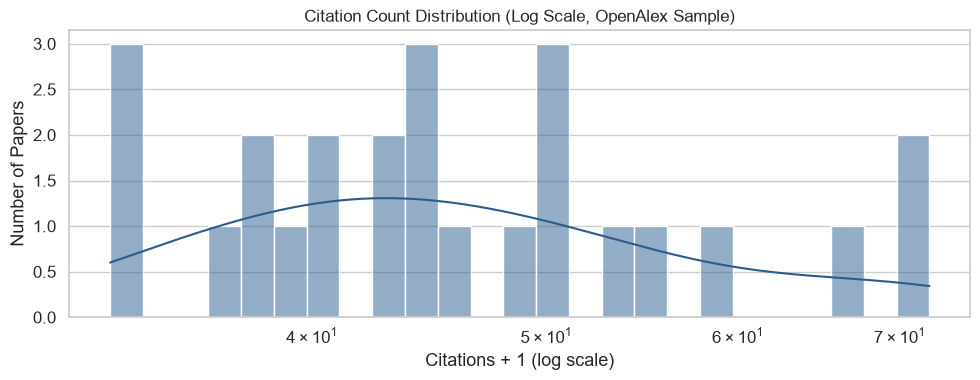

,title_norm,year,cited_by_count,venue
0,Optimized multivariate multiscale slope entrop...,2023,71,Chaos Solitons & Fractals
1,Detecting and diagnosing prior and likelihood ...,2023,69,Statistics and Computing
2,Optimal power distribution control in modular ...,2023,66,Applied Energy
3,TransVAE-DTA: Transformer and variational auto...,2023,58,Computer Methods and Programs in Biomedicine
4,ResfEANet: ResNet-fused External Attention Net...,2023,55,Computer Methods and Programs in Biomedicine U...


In [3]:
if not df_oa.empty and 'cited_by_count' in df_oa.columns:
    citations = df_oa['cited_by_count'].dropna()
    print('Citation summary statistics:')
    print(citations.describe())
    
    fig, ax = plt.subplots(figsize=(10, 4))
    sns.histplot(citations + 1, bins=25, log_scale=True, kde=True, ax=ax, color='#2b5c8f')
    ax.set_title('Citation Count Distribution (Log Scale, OpenAlex Sample)', fontsize=12)
    ax.set_xlabel('Citations + 1 (log scale)')
    ax.set_ylabel('Number of Papers')
    plt.tight_layout()
    plt.show()
    
    # Identify top cited papers in sample
    top_cited = df_oa.sort_values(by='cited_by_count', ascending=False)[['title_norm', 'year', 'cited_by_count', 'venue']].head(5)
    display(top_cited)

## 3. Research Question 2: Model Architecture and Ecosystem Velocity on Hugging Face

How does download traction concentrate among top text-generation models, and what licenses are attached to them?

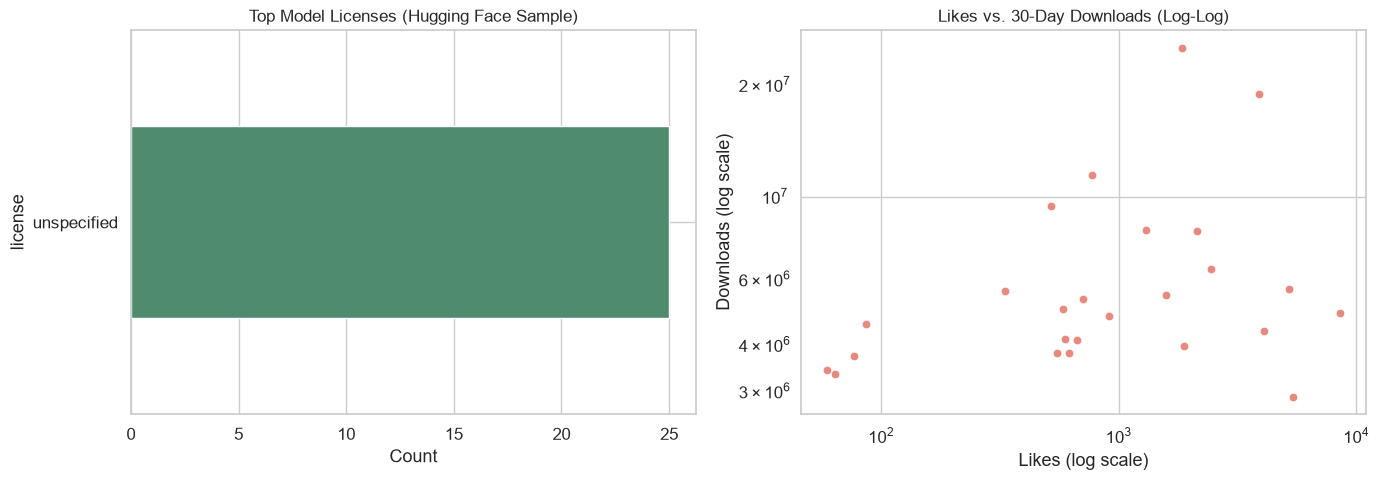

In [4]:
if not df_hf.empty and 'license' in df_hf.columns:
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    # License breakdown
    lic_counts = df_hf['license'].fillna('unspecified').value_counts().head(8)
    lic_counts.plot(kind='barh', ax=axes[0], color='#4f8c6f')
    axes[0].set_title('Top Model Licenses (Hugging Face Sample)', fontsize=12)
    axes[0].set_xlabel('Count')
    axes[0].invert_yaxis()
    
    # Likes vs Downloads correlation
    if 'likes' in df_hf.columns and 'downloads' in df_hf.columns:
        sns.scatterplot(data=df_hf, x='likes', y='downloads', alpha=0.8, ax=axes[1], color='#e26d5c')
        axes[1].set_xscale('log')
        axes[1].set_yscale('log')
        axes[1].set_title('Likes vs. 30-Day Downloads (Log-Log)', fontsize=12)
        axes[1].set_xlabel('Likes (log scale)')
        axes[1].set_ylabel('Downloads (log scale)')
        
    plt.tight_layout()
    plt.show()

## 4. Discussion of Biases and Methodological Gaps

1. **Preprint Over-Representation**: arXiv reflects papers submitted by self-selected authors primarily from mathematics, physics, and computer science. Traditional software engineering, biomedical applications, and humanities often publish elsewhere.
2. **Commercial vs. Open Repositories**: Hugging Face captures openly published model weights and checkpoints. Proprietary frontier models (e.g. OpenAI GPT-4, Google Gemini) do not have downloadable weights on HF, biasing open-hub analytics towards open-weights models.
3. **Sampling Scale**: The initial collection captures a verified sample (~50-100 per source) designed to validate end-to-end data pipelines safely without slamming API rate limits.

## 5. Research Question 5: Multi-Year Longitudinal Trends in AI Investment & Notable Systems (2013–2023)

How do macro trends in capital allocation and model production correlate over the 2013–2023 decade?

**Key Observations Grounded in Evidence:**
1. **Investment Super-Cycle**: Global private AI investment expanded from $6.01B in 2013 to a peak of $145.40B in 2021, before settling at $92.79B in 2023 (in constant 2021 US$).
2. **The Industry Hegemony Shift**: In 2013, academia produced more notable systems than industry (10 vs. 7). By 2023, industry accounted for 69 notable systems compared to 18 from academia, driven by massive compute and data capital requirements.


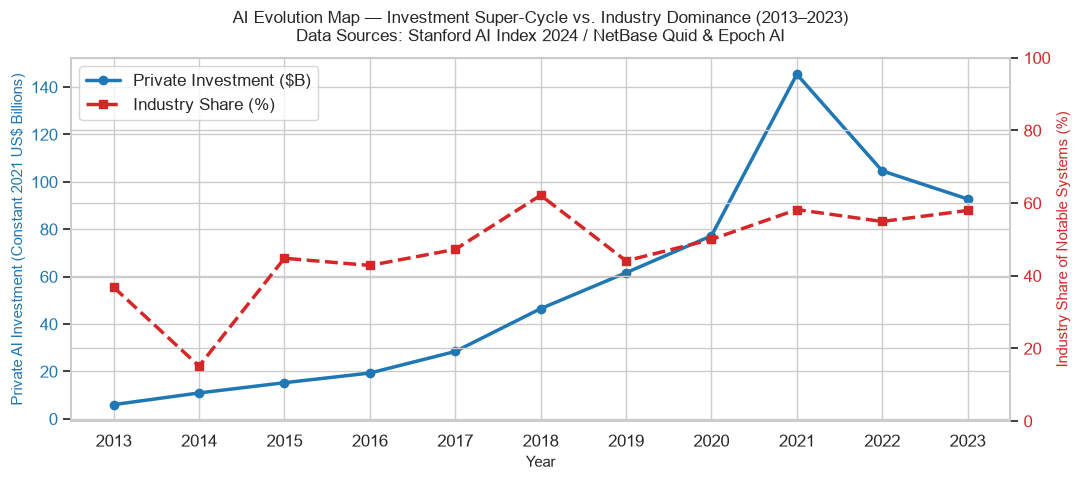

In [5]:
metrics_path = PROCESSED_DIR / 'metrics_validated.json'
if not metrics_path.exists():
    print('WARNING: metrics_validated.json not found.')
else:
    df_m = pd.DataFrame(json.load(open(metrics_path, encoding='utf-8')))
    
    # Extract private investment & industry share
    df_inv = df_m[df_m['metric_name'] == 'global_private_ai_investment_annual_constant_2021_usd_billions'].copy()
    df_ind = df_m[df_m['metric_name'] == 'notable_ai_systems_annual_count_industry'].copy()
    df_tot = df_m[df_m['metric_name'] == 'notable_ai_systems_annual_count_total'].copy()

    df_inv['year'] = df_inv['period'].astype(int)
    df_ind['year'] = df_ind['period'].astype(int)
    df_tot['year'] = df_tot['period'].astype(int)

    merged = pd.merge(df_inv[['year', 'value']].rename(columns={'value': 'investment_b'}),
                      df_ind[['year', 'value']].rename(columns={'value': 'industry_systems'}), on='year')
    merged = pd.merge(merged, df_tot[['year', 'value']].rename(columns={'value': 'total_systems'}), on='year')
    merged['industry_pct'] = (merged['industry_systems'] / merged['total_systems']) * 100

    fig, ax1 = plt.subplots(figsize=(11, 5))
    color_inv = '#1f77b4'
    ax1.set_xlabel('Year', fontsize=11)
    ax1.set_ylabel('Private AI Investment (Constant 2021 US$ Billions)', color=color_inv, fontsize=11)
    line1 = ax1.plot(merged['year'], merged['investment_b'], color=color_inv, marker='o', linewidth=2.5, label='Private Investment ($B)')
    ax1.tick_params(axis='y', labelcolor=color_inv)
    ax1.set_xticks(merged['year'])

    ax2 = ax1.twinx()
    color_pct = '#d62728'
    ax2.set_ylabel('Industry Share of Notable Systems (%)', color=color_pct, fontsize=11)
    line2 = ax2.plot(merged['year'], merged['industry_pct'], color=color_pct, marker='s', linewidth=2.5, linestyle='--', label='Industry Share (%)')
    ax2.tick_params(axis='y', labelcolor=color_pct)
    ax2.set_ylim(0, 100)

    lines = line1 + line2
    labels = [l.get_label() for l in lines]
    ax1.legend(lines, labels, loc='upper left', frameon=True)

    plt.title('AI Evolution Map — Investment Super-Cycle vs. Industry Dominance (2013–2023)\nData Sources: Stanford AI Index 2024 / NetBase Quid & Epoch AI', fontsize=12, pad=12)
    plt.tight_layout()
    plt.show()
